# The Unscented Kalman Filter (UKF)

Course: Recursive State Estimation for Dynamic Systems (SoSe 2026)

Institute: Geodätisches Institut Hannover

Team Members :

1.Arjun Mohandas( Matriculation Nummer:10081891)

2.Aswin Sam(Matriculation Nummer:10082498)

3.Edvin Tony Thampy(Matriculation Nummer:10082986)

This notebook implements the Unscented kalman Filter (UKF) for estimating the 3D position and velocity of a robot from noisy total-station observations.The unconstrained UKF is implemented and documented.

The implementation follows the notation used in the lecture and exercise sessions.

## Use Of AI

ChatGPT was used for coding review, debugging assistance and researching information.It was mainly used to summarise topics and informations and document them into latex code including equations which were too lengthy and time consuming too write.It was used to understand and minimize code implementations and document information, handle data, plot graphs and diagrams with ease. It was mainly used to check for errors in code and evaluate diagrams to understand their behaviour.The implementations differed from filter to filter.Eventhough AI was used all implementation decisions and final results were verified by us.

# AIM

The EKF and IEKF estimate nonlinear systems by approximating nonlinear functions using a first-order Taylor series expansion. This approximation is only locally accurate and may introduce significant errors when the system exhibits strong nonlinear behavior.

Instead of approximating the nonlinear function, the aim of the UKF is to find the final state estimate by approximating the probability distribution of the state after passing through the nonlinear transformation. This is achieved using a deterministic set of sigma points that preserve the mean and covariance of the state distribution.

Each sigma point is propagated through the nonlinear system model and measurement model. The transformed sigma points are then used to reconstruct the predicted mean and covariance.


##  State and Measurement Models

$$
\mathbf{x}^{(k)} =
\begin{bmatrix}
X^{(k)} \\
Y^{(k)} \\
Z^{(k)} \\
V_X^{(k)} \\
V_Y^{(k)} \\
V_Z^{(k)}
\end{bmatrix}
$$

### The dynamic system model is

$$
\mathbf{x}^{(k)}
=
\mathbf{\Phi}
\mathbf{x}^{(k-1)}
+
\mathbf{w}^{(k-1)}
$$

where $$
\mathbf{w}^{(k-1)}
\sim
\mathcal{N}
\left(
\mathbf{0},
\mathbf{Q}_{ww}
\right)
$$

The nonlinear observation model is

$$
\mathbf{l}^{(k)}
=
h\!\left(\mathbf{x}^{(k)}\right)
+
\mathbf{v}^{(k)}
$$

where

$$
\mathbf{l}^{(k)}
=
\begin{bmatrix}
H^{(k)}\\
V^{(k)}\\
D^{(k)}
\end{bmatrix}
$$

contains

- Horizontal angle,
- Vertical angle,
- Distance.

The observation noise is assumed to be Gaussian,

$$
\mathbf{v}^{(k)}
\sim
\mathcal{N}\!\left(\mathbf{0},\,\mathbf{R}^{(k)}\right).
$$


# PRE-PROCESSING

## Imports and Loading given datafiles

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time

# Read observation and ground truth data
obsrv = pd.read_csv("Data/polar0011_slower_0.csv")
gtrue = pd.read_csv("Data/tracker0011_slower_0.csv")

In [2]:
#finding step length dt....

obsrv["time"] = pd.to_datetime(obsrv["Time [HH:MM:SS]"],format="%H:%M:%S.%f") # convert to timestamp 
time_inseconds=(obsrv["time"]-obsrv["time"].iloc[0]) # subtract the column from first timestap to get time in seconds
time_inseconds = time_inseconds.dt.total_seconds()# .dt.total_seconds to get seconds
time_inseconds= time_inseconds.values# convert to np arrays
dt= np.mean(np.diff(time_inseconds)) #Take mean of differences and round it.
dt=round(dt,3)

In [3]:
#Conversion of observations from polar coordinates to cartesian coordinates:
obsrv["H_radian"] = np.deg2rad(obsrv["H [deg]"]) #degree to radian conversion
obsrv["V_radian"]= np.deg2rad(obsrv["V [deg]"])
obsrv["D_m"]= obsrv["D [mm]"] / 1000  #mm to m conversion

X_obsrv = obsrv["D_m"]*np.sin(obsrv["V_radian"])*np.cos(obsrv["H_radian"] )

Y_obsrv = obsrv["D_m"]*np.sin(obsrv["V_radian"])*np.sin(obsrv["H_radian"] )

Z_obsrv = obsrv["D_m"]*np.cos(obsrv["V_radian"])

obsrv["X_obsrv_cart"] = X_obsrv
obsrv["Y_obsrv_cart"] = Y_obsrv
obsrv["Z_obsrv_cart"] = Z_obsrv

X_gtrue = gtrue["X [m]"].values #converting pandas to numpy
Y_gtrue = gtrue["Y [m]"].values
Z_gtrue = gtrue["Z [m]"].values


In [4]:
#system matrices.....

#step length
dt=0.01 

#state_matrix

X0 = obsrv["X_obsrv_cart"].iloc[0]
Y0 = obsrv["Y_obsrv_cart"].iloc[0]
Z0 = obsrv["Z_obsrv_cart"].iloc[0]

X_k= np.array([X0,Y0,Z0,0,0,0])  # velocities are unknown initially

#Transition matrix
#The time step dt is use to build the transition matrix.
Phi_k = np.array([
    [1,0,0,dt,0,0],
    [0,1,0,0,dt,0],
    [0,0,1,0,0,dt],
    [0,0,0,1,0,0],
    [0,0,0,0,1,0],
    [0,0,0,0,0,1]])

sigma_a=2.5

#Then derive Q_ww usimg sigma_a:
Q_ww = sigma_a**2 * np.array([
    [dt**4/4,0,0,dt**3/2,0,0],
    [0,dt**4/4,0,0,dt**3/2,0],
    [0,0,dt**4/4,0,0,dt**3/2],
    [dt**3/2,0,0,dt**2,0,0],
    [0,dt**3/2,0,0,dt**2,0],
    [0,0,dt**3/2,0,0,dt**2]])


In [5]:
#Jacobian Function
#we should convert polar to cartesian using jacobian.
def observation_jacobian(H_radian, V_radian, D_m):
    return np.array([[-D_m * np.sin(V_radian) * np.sin(H_radian),
            D_m * np.cos(V_radian) * np.cos(H_radian),
            np.sin(V_radian) * np.cos(H_radian)],
            [D_m * np.sin(V_radian) * np.cos(H_radian),
            D_m * np.cos(V_radian) * np.sin(H_radian),
            np.sin(V_radian) * np.sin(H_radian)],
            [0,-D_m * np.sin(V_radian),np.cos(V_radian)]])


#Initial or State covariance matrix,Q_xx

sigma_H = np.deg2rad(0.0014)#given in task description
sigma_V = np.deg2rad(0.0014)#given in task description
D_0 = obsrv["D_m"].iloc[0] # Distance for zeroth measurement
sigma_D0 = 0.0025 * D_0+ 0.0025 # Equation provided in task description
Q_HVD0 = np.diag([
    sigma_H**2,
    sigma_V**2,
    sigma_D0**2])# Polar covariance matrix

J0 = observation_jacobian(
    obsrv["H_radian"].iloc[0],
    obsrv["V_radian"].iloc[0],
    obsrv["D_m"].iloc[0])

Q_XYZ0 = J0 @ Q_HVD0 @ J0.T

Q_xx = np.diag([
    Q_XYZ0[0,0],   # X variance
    Q_XYZ0[1,1],   # Y variance
    Q_XYZ0[2,2],   # Z variance
    1,             # Vx variance
    1,             # Vy variance
    1])            # Vz variance



In [6]:
## Nonlinear Observation Function

def h(x):
    X = x[0] 
    Y = x[1]
    Z = x[2]

    D = np.sqrt(X**2 + Y**2 + Z**2) #slope

    H = np.arctan2(Y,X)# horizontal angle

    V = np.arccos(Z/D) #zenith angle

    return np.array([H,V,D])


# PROCEDURE
# The Unscented Transform (UT)

The EKF and IEKF estimates the robot state by linearizing the nonlinear measurement function around the predicted state,

$$
h\!\left(\mathbf{X}^{(k)-}\right).
$$

This linearization uses a first-order Taylor series approximation, which is accurate only when the system is nearly linear and the state uncertainty is small. For highly nonlinear systems, the approximation introduces errors in the predicted mean and covariance, reducing the estimation accuracy.

The Unscented Transform overcomes this limitation by propagating the probability distribution instead of linearizing the nonlinear function.

Rather than using only the predicted state, the UT generates a set of carefully chosen **sigma points** around the predicted mean using the covariance matrix. Each sigma point is passed through the nonlinear measurement function, and the transformed points are combined to obtain the predicted mean and covariance.

Since the true nonlinear function is used directly, no Taylor series approximation or Jacobian matrix is required.


#  Unscented Transform Parameters

##  State Dimension

The state vector is
$$
\mathbf{X}^{(k)-}
=
\begin{bmatrix}
x \\
y \\
z \\
v_x \\
v_y \\
v_z
\end{bmatrix}.
$$


The dimension of the state vector is therefore

$$
n=6.
$$

The Unscented Transform generates

$$
2n+1
$$

sigma points at each filtering epoch.

##  Scaling Parameters

Three parameters control the distribution of the sigma points around the predicted mean.

### (a) Parameter $\alpha$

The parameter $\alpha$ determines the spread of the sigma points around the predicted state estimate. A small value of $\alpha$ places the sigma points close to the predicted mean, whereas a larger value spreads the sigma points farther away.

Hence we use a small positive value such as

$$
\alpha = 10^{-3}
$$


### (b) Parameter $\beta$

The parameter $\beta$ incorporates prior knowledge of the probability distribution.
Since the process and measurement noises in this work are assumed to follow Gaussian distributions, the value

$$
\beta = 2
$$

is adopted.

### (c) Parameter $\kappa$

The parameter $\kappa$ is a secondary scaling parameter that provides additional control over the sigma point distribution.

A commonly used value is

$$
\kappa = 0,
$$

and we select it.

## Composite Scaling Parameter

The three parameters are combined to form the scaling parameter

$$
\lambda
=
\alpha^{2}(n+\kappa)-n.
$$

The value of $\lambda$ determines the distance of the sigma points from the predicted mean and is also used in the computation of the sigma point weights.

In [7]:
#Scaling parameters
n = 6 #state parameter

alpha = 1e-3 #smaller value close to mean
beta  = 2 # depend on previous distribution/good value for gaussian
kappa = 0 # additional sp/ stable sigma point generation

lambda_= alpha**2 * (n + kappa) - n


##  Sigma Point Weights

After generating the sigma points, each sigma point is assigned a corresponding weight. These weights determine the contribution of each sigma point towards the computation of the predicted state mean and the predicted covariance.

Two different sets of weights are required:

- Mean weights, denoted by $W_i^{(m)}$, are used to compute the predicted state estimate.
- Covariance weights, denoted by $W_i^{(c)}$, are used to compute the predicted covariance matrix.

The first sigma point represents the mean of the Gaussian distribution and therefore carries a different weight from the remaining sigma points. All remaining sigma points represent symmetric deviations about the mean and consequently receive identical weights.


### Mean Weights

The first mean weight is computed as

$$
W_0^{(m)}
=
\frac{\lambda}{n+\lambda}.
$$

The remaining mean weights are

$$
W_i^{(m)}
=
\frac{1}{2(n+\lambda)},
\qquad
i=1,2,\ldots,2n.
$$

### Covariance Weights

The first covariance weight is

$$
W_0^{(c)}
=
\frac{\lambda}{n+\lambda}
+
\left(
1-\alpha^2+\beta
\right).
$$

The remaining covariance weights are

$$
W_i^{(c)}
=
\frac{1}{2(n+\lambda)},
\qquad
i=1,2,\ldots,2n.
$$

### Significance of the Correction Term

Unlike the mean weights, the covariance weight of the first sigma point contains the additional correction term

$$
1-\alpha^2+\beta.
$$

This term is introduced in the **Scaled Unscented Transform** to improve the approximation of the covariance after the sigma points undergo a nonlinear transformation.


In [8]:
# Sigma Point Weights

Wm = np.zeros(2 * n + 1)
Wc = np.zeros(2 * n + 1)

# First weight

Wm[0] = lambda_ / (n + lambda_)

Wc[0] = (lambda_ / (n + lambda_)+ (1 - alpha**2 + beta))

# Remaining weights

for i in range(1, 2 * n + 1):

    Wm[i] = 1 / (2 * (n + lambda_))

    Wc[i] = 1 / (2 * (n + lambda_))


## Sigma Point Generation


The sigma points are generated from the predicted state estimate and its predicted covariance matrix as follows.

First, compute the Cholesky factor of the scaled predicted covariance matrix,

$$
L
=
\operatorname{chol}
\left(
(n+\lambda)\,Q_{xx}^{-}
\right).
$$

The first sigma point is equal to the predicted state estimate,

$$
\chi_{0}
=
X_{k}^{-}.
$$

The positive sigma points are generated as

$$
\chi_{i}
=
X_{k}^{-}
+
L_{i},
\qquad
i=1,2,\ldots,n.
$$

The negative sigma points are generated as

$$
\chi_{i+n}
=
X_{k}^{-}
-
L_{i},
\qquad
i=1,2,\ldots,n.
$$

where $L_i$ denotes the $i^{\text{th}}$ column of the Cholesky factor $L$.

The covariance matrix contains not only the uncertainty of each state but also the correlations between states. Using the Cholesky decomposition,

$$
\mathbf{Q}_{xx}^{(k)-}
=
\mathbf{L}\mathbf{L}^{T},
$$

provides a computationally efficient and numerically stable method for generating sigma points that exactly reproduce the covariance matrix. For this reason, Cholesky decomposition is the standard approach used in the Scaled Unscented Kalman Filter.

In [9]:
# Sigma Point Generation
# The 13 sigma points are generated here using cholesky decomposition and cholesky factor.
def generate_sigma_points(X_k_minus,Q_xx_minus):

    # Cholesky factor

    L = np.linalg.cholesky((n + lambda_) * Q_xx_minus)

    # Sigma point matrix

    sigma_points = np.zeros((n, 2*n + 1))

    # First sigma point

    sigma_points[:,0] = X_k_minus

    # Remaining sigma points

    for i in range(n):

        sigma_points[:,i+1] = (X_k_minus+ L[:,i])

        sigma_points[:,i+1+n] = (X_k_minus- L[:,i])

    return sigma_points



### Prediction step begins
#Each sigma point is propogated through the state model
# Sigma Point Prediction
def predict_sigma_points(sigma_points):

    sigma_points_minus = np.zeros_like(sigma_points)

    for i in range(2 * n + 1):

        sigma_points_minus[:,i] = (Phi_k @ sigma_points[:,i])

    return sigma_points_minus

##  Prediction of Sigma Points

After generating the sigma points, each sigma point is independently propagated through the system process model. Since the state transition model is linear, the predicted sigma points are computed as

$$
\chi_i^{(k)-}
=
\mathbf{\Phi}^{(k)}
\chi_i^{(k)},
\qquad
i=0,1,\ldots,2n.
$$

where

- $\mathbf{\Phi}^{(k)}$ is the state transition matrix,
- $\chi_i^{(k)}$ is the $i^{\text{th}}$ sigma point before prediction,
- $\chi_i^{(k)-}$ is the predicted sigma point.

##  Predicted State Estimate Mean

Once all sigma points have been propagated through the process model, the predicted state estimate is obtained as the weighted mean of the propagated sigma points,

$$
\mathbf{X}^{(k)-}
=
\sum_{i=0}^{2n}
W_i^{(m)}
\chi_i^{(k)-}.
$$

where

- $W_i^{(m)}$ is the mean weight of the $i^{\text{th}}$ sigma point,
- $\chi_i^{(k)-}$ is the predicted sigma point.

The weighted mean represents the best estimate of the system state after the prediction step.

##  Predicted State Covariance

The predicted covariance matrix is computed from the weighted spread of the propagated sigma points about the predicted state estimate as

$$
\mathbf{Q}_{xx}^{(k)-}
=
\sum_{i=0}^{2n}
W_i^{(c)}
\left(
\chi_i^{(k)-}
-
\mathbf{X}^{(k)-}
\right)
\left(
\chi_i^{(k)-}
-
\mathbf{X}^{(k)-}
\right)^T
+
\mathbf{Q}_{ww}^{(k)}.
$$

where

- $W_i^{(c)}$ is the covariance weight of the $i^{\text{th}}$ sigma point,
- $\mathbf{Q}_{ww}^{(k)}$ is the process noise covariance matrix.

The first term represents the uncertainty resulting from the propagated sigma points, while the second term accounts for the uncertainty introduced by the process noise.

In [10]:
# Predicted State Mean
def predict_state_mean(sigma_points_minus):

    X_k_minus = np.zeros(n)

    for i in range(2 * n + 1):

        X_k_minus += (Wm[i]* sigma_points_minus[:,i])

    return X_k_minus

# Predicted State Covariance
def predict_state_covariance(sigma_points_minus,X_k_minus):

    Q_xx_minus = np.zeros((n,n))

    
    for i in range(2 * n + 1):

        dx = (sigma_points_minus[:,i]- X_k_minus)
        

        Q_xx_minus += (Wc[i]* np.outer(dx,dx)) # dxdx transpose

    Q_xx_minus += Q_ww

    return Q_xx_minus


### Measurement Prediction

We generate sigma points again from the predicted state estimate,
$\mathbf{X}^{(k)-}$, and the predicted covariance matrix,
$\mathbf{Q}_{xx}^{(k)-}$.

This is a major difference from the Extended Kalman Filter (EKF). Instead of computing the Jacobian matrix of the nonlinear measurement function, the predicted sigma points are propagated directly through the nonlinear measurement function,

$$
h\!\left(\chi_i^{(k)-}\right),
\qquad
i=0,1,\ldots,2n,
$$

to produce the corresponding **measurement sigma points**. Hence sigma points generation takes place two times.

In [11]:
# Measurement Sigma Points
def predict_measurement_sigma_points(sigma_points_measurement):

    measurement_sigma_points = np.zeros((3, 2*n + 1))

    for i in range(2*n + 1):

        measurement_sigma_points[:,i] = h(sigma_points_measurement[:,i])

    return measurement_sigma_points
  

## Predicted Measurement Mean

The predicted sigma points are propagated through the nonlinear measurement function to obtain the corresponding **measurement sigma points**. Unlike the EKF, no Jacobian matrix is required.

For each predicted sigma point,

$$
\chi_i^{(k)-},
\qquad
i=0,1,\ldots,2n,
$$

the corresponding measurement sigma point is

$$
\mathbf{l}_i^{(k)}
=
h\!\left(\chi_i^{(k)-}\right),
$$

where

$$
\mathbf{l}_i^{(k)}
=
\begin{bmatrix}
H_i^{(k)}\\
V_i^{(k)}\\
D_i^{(k)}
\end{bmatrix}.
$$

The predicted measurement mean is computed as the weighted average of all measurement sigma points,

$$
\hat{\mathbf{l}}^{(k)-}
=
\sum_{i=0}^{2n}
W_i^{(m)}
\mathbf{l}_i^{(k)}.
$$

Since the horizontal angle is a periodic quantity, its mean is computed using the circular mean,

$$
\hat{H}^{(k)-}
=
\operatorname{atan2}
\left(
\sum_{i=0}^{2n}
W_i^{(m)}
\sin\!\left(H_i^{(k)}\right),
\;
\sum_{i=0}^{2n}
W_i^{(m)}
\cos\!\left(H_i^{(k)}\right)
\right).
$$

The vertical angle and distance are computed using the weighted arithmetic mean,

$$
\hat{V}^{(k)-}
=
\sum_{i=0}^{2n}
W_i^{(m)}
V_i^{(k)},
$$

$$
\hat{D}^{(k)-}
=
\sum_{i=0}^{2n}
W_i^{(m)}
D_i^{(k)}.
$$

Hence, the predicted measurement vector is

$$
\hat{\mathbf{l}}^{(k)-}
=
\begin{bmatrix}
\hat{H}^{(k)-}\\
\hat{V}^{(k)-}\\
\hat{D}^{(k)-}
\end{bmatrix}.
$$

The predicted measurement mean represents the expected sensor measurement corresponding to the predicted state estimate. By averaging the transformed sigma points instead of linearizing the measurement model, the UKF captures nonlinear effects more accurately.

In [12]:
# Predicted Measurement Mean
def predict_measurement_mean(measurement_sigma_points):

    l_k_minus = np.zeros(3)
    
    # Horizontal angle (circular mean)
    sin_sum = 0.0
    cos_sum = 0.0

    for i in range(2*n + 1):

        sin_sum += (Wm[i]* np.sin(measurement_sigma_points[0,i]))

        cos_sum += (Wm[i]* np.cos(measurement_sigma_points[0,i]))

    l_k_minus[0] = np.arctan2(sin_sum,cos_sum)

    # Zenith angle
    
    for i in range(2*n + 1):

        l_k_minus[1] += (Wm[i]* measurement_sigma_points[1,i])
    # Distance

    for i in range(2*n + 1):

        l_k_minus[2] += (Wm[i]* measurement_sigma_points[2,i])

    return l_k_minus

### Predicted Measurement Covariance

The predicted measurement covariance represents the uncertainty of the predicted measurement. It is computed from the weighted covariance of the measurement sigma points together with the measurement noise covariance.

The measurement deviation for each sigma point is

$$
\Delta \mathbf{l}_i^{(k)}
=
\mathbf{l}_i^{(k)}
-
\hat{\mathbf{l}}^{(k)-}.
$$

Since the horizontal angle is periodic, its difference is wrapped to the interval $[-\pi,\pi]$ using

$$
\Delta H_i^{(k)}
=
\operatorname{atan2}
\left(
\sin\!\left(\Delta H_i^{(k)}\right),
\cos\!\left(\Delta H_i^{(k)}\right)
\right).
$$

The predicted measurement covariance is then

$$
\mathbf{Q}_{ll}^{(k)}
=
\sum_{i=0}^{2n}
W_i^{(c)}
\Delta \mathbf{l}_i^{(k)}
\Delta \mathbf{l}_i^{(k)T}
+
\mathbf{Q}_{HVD}^{(k)}.
$$

Unlike the EKF, which computes the innovation covariance using the measurement Jacobian, the UKF directly estimates the covariance from the transformed measurement sigma points, allowing the nonlinear behaviour of the measurement model to be captured without linearization.

In [13]:
# Predicted Measurement Covariance
def predict_measurement_covariance(measurement_sigma_points,l_k_minus,Q_HVD):

    Q_zz = np.zeros((3,3))

    for i in range(2*n + 1):

        dz = (measurement_sigma_points[:,i]- l_k_minus)

        # Horizontal angle wrapping

        dz[0] = np.arctan2(
            np.sin(dz[0]),
            np.cos(dz[0]))

        Q_zz += (Wc[i]* np.outer(dz,dz))

    Q_zz += Q_HVD

    return Q_zz

## Cross Covariance

The cross covariance describes the relationship between the uncertainty in the predicted state and the uncertainty in the predicted measurement.

The state deviation for each sigma point is

$$
\Delta \mathbf{X}_i^{(k)}
=
\chi_i^{(k)-}
-
\mathbf{X}^{(k)-},
$$

and the measurement deviation is

$$
\Delta \mathbf{l}_i^{(k)}
=
\mathbf{l}_i^{(k)}
-
\hat{\mathbf{l}}^{(k)-}.
$$

Since the horizontal angle is periodic, its difference is wrapped to the interval $[-\pi,\pi]$,

$$
\Delta H_i^{(k)}
=
\operatorname{atan2}
\left(
\sin\!\left(\Delta H_i^{(k)}\right),
\cos\!\left(\Delta H_i^{(k)}\right)
\right).
$$

The predicted cross covariance is then computed as

$$
\mathbf{Q}_{xl}^{(k)}
=
\sum_{i=0}^{2n}
W_i^{(c)}
\Delta \mathbf{X}_i^{(k)}
\Delta \mathbf{l}_i^{(k)T}.
$$

The matrix $\mathbf{Q}_{xl}^{(k)}$ measures how uncertainties in the state affect the predicted measurements. In the EKF, this relationship is obtained using the measurement Jacobian $\mathbf{H}(\mathbf{X})$. In contrast, the UKF estimates it directly from the propagated sigma points, eliminating the need for Jacobian matrices. The cross covariance is then used to compute the Kalman gain.

In [14]:
# Cross Covariance
def predict_cross_covariance(sigma_points_minus,X_k_minus,measurement_sigma_points,l_k_minus):

    Q_xz = np.zeros((n,3))

    for i in range(2 * n + 1):

        dx = (sigma_points_minus[:,i]- X_k_minus)

        dz = (measurement_sigma_points[:,i]- l_k_minus)

        # Horizontal angle wrapping

        dz[0] = np.arctan2(
            np.sin(dz[0]),
            np.cos(dz[0]))

        Q_xz += (Wc[i]* np.outer(dx,dz))

    return Q_xz

## Kalman Gain

Unlike the EKF, the UKF does not require the measurement Jacobian. Instead, the relationship between the state and the measurement is obtained directly from the predicted cross covariance.The Kalman Gain is computed as

$$
K_k
=
Q_{XZ,k}
Q_{ZZ,k}^{-1}.
$$

where,

- $Q_{XZ,k}$ is the predicted cross covariance,
- $Q_{ZZ,k}$ is the predicted measurement covariance.


In [15]:
# Kalman Gain
def compute_kalman_gain(Q_xz,Q_zz):

    K = (Q_xz@ np.linalg.inv(Q_zz))

    return K    

## Innovation (Measurement Residual)

The innovation is computed as

$$
I_k
=
l_k
-
\hat{l}_k^{-},
$$

where

- $l_k$ is the actual measurement vector,
- $\hat{l}_k^{-}$ is the predicted measurement mean.


In [16]:
# Innovation (Measurement Residual)
def innovation(l_k,l_k_minus):

    I = (l_k- l_k_minus)

    # Horizontal angle wrapping
   
    I[0] = np.arctan2(
        np.sin(I[0]),
        np.cos(I[0]))

    return I

## State Update

The state update equation is

$$
\hat{X}_k^{+}
=
\hat{X}_k^{-}
+
K_kI_k.
$$


In [17]:
def update_state(X_k_minus,K,I):

    X_k_plus = (X_k_minus+ K @ I)

    return X_k_plus

## Covariance Update

The updated state covariance is computed as

$$
Q_{xx,k}^{+}
=
Q_{xx,k}^{-}
-
K_kQ_{ZZ,k}K_k^{T}.
$$

The matrix $K_kQ_{ZZ,k}K_k^{T}$ represents the amount of uncertainty removed by incorporating the current measurement. 

In [18]:
def update_covariance(Q_xx_minus,K,Q_zz):

    Q_xx_plus = (Q_xx_minus- K @ Q_zz @ K.T)

    return Q_xx_plus

In [19]:
N = len(obsrv)

estimates_ukf= np.zeros((N,6))
X_plus_history_ukf= np.zeros((N, 6))
Q_plus_history_ukf = np.zeros((N, 6, 6))

estimates_ukf[0] = X_k
X_plus_history_ukf[0] = X_k
Q_plus_history_ukf[0] = Q_xx

# Start Timing
start_time = time.perf_counter()

for k in range(1, N):

    #Actual Measuremnent

    l_k = np.array([
        obsrv["H_radian"].iloc[k],
        obsrv["V_radian"].iloc[k],
        obsrv["D_m"].iloc[k]])
    
#Observation/measurement covariance
    
    sigma_H = np.deg2rad(0.0014) # given 

    sigma_V = np.deg2rad(0.0014) #given

    sigma_D = (0.0025 *obsrv["D_m"].iloc[k]+ 0.0025) #given

    Q_HVD = np.diag([sigma_H**2,
                             sigma_V**2,
                             sigma_D**2])   
    # Prediction
    
    sigma_points = generate_sigma_points(X_k,Q_xx)

    sigma_points_minus = predict_sigma_points(sigma_points)

    X_k_minus = predict_state_mean(sigma_points_minus)

    Q_xx_minus = predict_state_covariance(sigma_points_minus,X_k_minus)
    
    # Measurement
   
    sigma_points_measurement = generate_sigma_points(X_k_minus,Q_xx_minus) 

    measurement_sigma_points = (predict_measurement_sigma_points(sigma_points_measurement))

    l_k_minus = predict_measurement_mean(measurement_sigma_points)

    Q_zz = predict_measurement_covariance(measurement_sigma_points,l_k_minus,Q_HVD)

    Q_xz = predict_cross_covariance(sigma_points_measurement,X_k_minus,measurement_sigma_points,l_k_minus)
    
    # Update step
    
    K_k = compute_kalman_gain(Q_xz,Q_zz)

    I_k = innovation(l_k,l_k_minus)

    X_k_plus = update_state(X_k_minus,K_k,I_k)

    Q_xx_plus = update_covariance(Q_xx_minus,K_k,Q_zz)

    # Save Results
    
    estimates_ukf[k] = X_k_plus

    X_plus_history_ukf[k] = X_k_plus

    Q_plus_history_ukf[k] = Q_xx_plus

    # Update next epoch

    X_k = X_k_plus

    Q_xx = Q_xx_plus

    # Stop Timing

    end_time = time.perf_counter()

    computation_time = end_time - start_time

#Extracting Estimates....

X_est = estimates_ukf[:,0]

Y_est = estimates_ukf[:,1]

Z_est = estimates_ukf[:,2]

Vx_est = estimates_ukf[:,3]

Vy_est = estimates_ukf[:,4]

Vz_est = estimates_ukf[:,5]

print("="*60)
print("COMPUTATION TIME FOR UKF")
print("="*60)

print(f"Total Time : {computation_time:.6f} s")

print(f"Average Time per Epoch : {computation_time/(N-1):.8f} s")

print(f"Average Time per Epoch : {(computation_time/(N-1))*1000:.4f} ms")

print("="*60)


COMPUTATION TIME FOR UKF
Total Time : 7.217124 s
Average Time per Epoch : 0.00102284 s
Average Time per Epoch : 1.0228 ms


In [20]:
# Ground Truth Velocity
Vx_gtrue = np.gradient(X_gtrue, dt)
Vy_gtrue = np.gradient(Y_gtrue, dt)
Vz_gtrue = np.gradient(Z_gtrue, dt)

## OBSERVATIONS

## 1. 2D Estimated UKF vs Ground Truth Trajectory


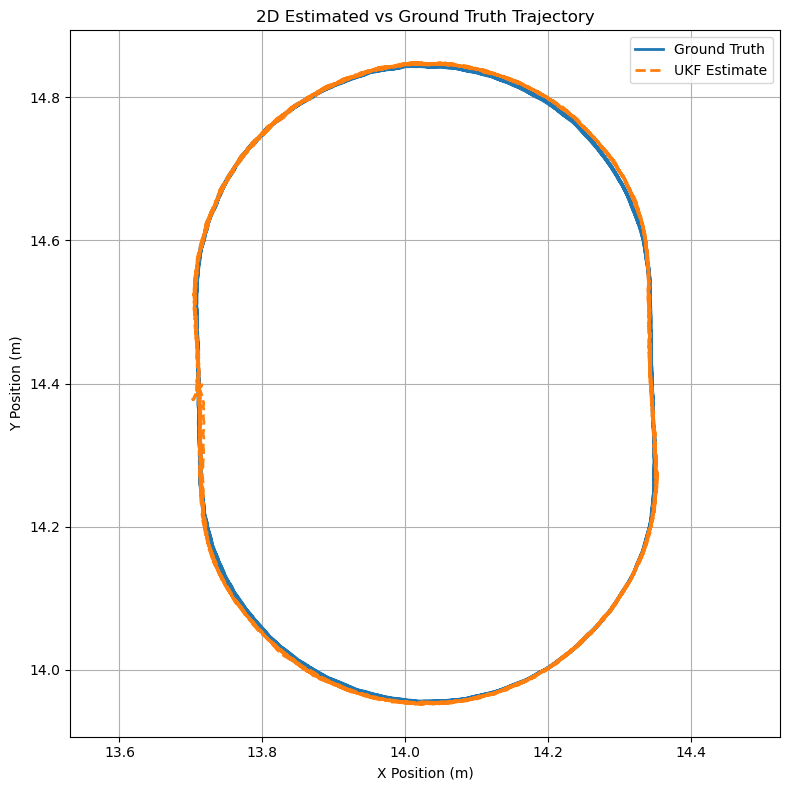

In [21]:

plt.figure(figsize=(8,8))

# Ground Truth Trajectory
plt.plot(
    X_gtrue,
    Y_gtrue,
    label='Ground Truth',
    linewidth=2)

# UKF Estimated Trajectory
plt.plot(
    X_est,
    Y_est,
    '--',
    label='UKF Estimate',
    linewidth=2)

plt.title('2D Estimated vs Ground Truth Trajectory')
plt.xlabel('X Position (m)')
plt.ylabel('Y Position (m)')

plt.axis('equal')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.savefig("Figures/UKF_2D_Trajectory.png",
    dpi=300,
    bbox_inches="tight")
plt.show()

- The 2D trajectory comparison demonstrates that the Unscented Kalman Filter (UKF) accurately estimates the vehicle trajectory, with the estimated path closely following the ground truth throughout the complete trajectory.
  
- Small deviations are observed primarily near the curved regions and at the turning points, where the vehicle experiences changes in direction and the constant-velocity motion model is less representative of the true dynamics.

- The trajectory remains smooth and continuous throughout the experiment without oscillations, discontinuities, or abrupt corrections, demonstrating stable recursive estimation. No evidence of filter divergence or numerical instability is observed, confirming that the UKF remains stable over the entire trajectory.


## 2. Component wise Absolute deviation between estimated and ground truth 3D position over time

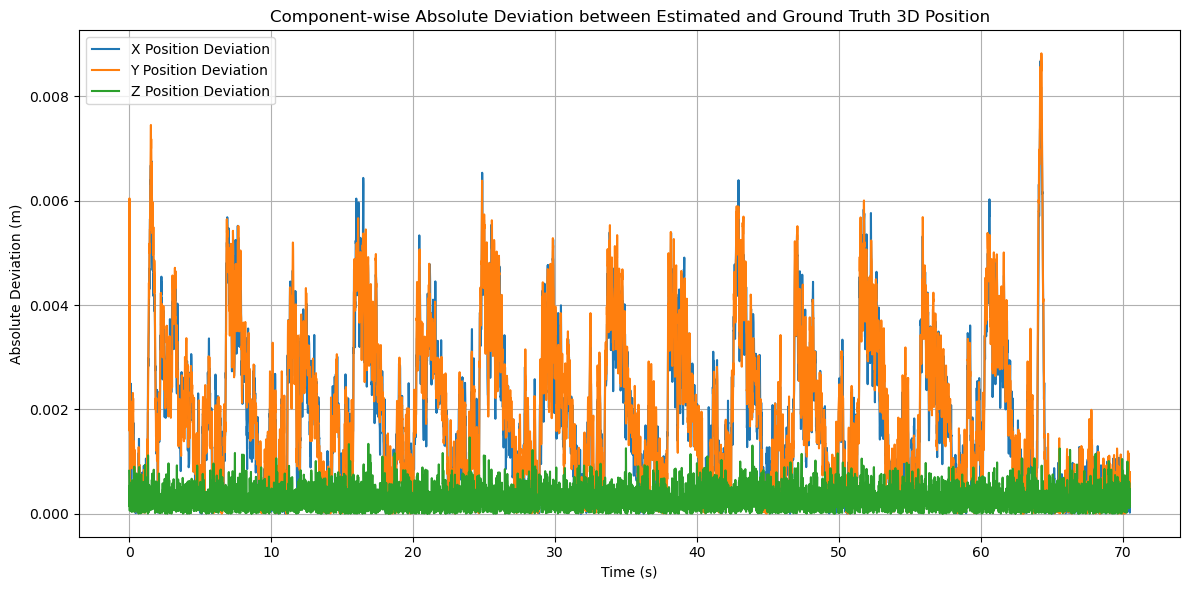

ABSOLUTE POSITION DEVIATIONS
Maximum X Deviation (m) : 0.008678531329
Mean X Deviation (m)    : 0.001869937396

Maximum Y Deviation (m) : 0.008824370721
Mean Y Deviation (m)    : 0.001925234895

Maximum Z Deviation (m) : 0.001463187055
Mean Z Deviation (m)    : 0.000287061423


In [22]:
# Absolute Position Deviations
abs_dev_x = np.abs(X_est - X_gtrue)
abs_dev_y = np.abs(Y_est - Y_gtrue)
abs_dev_z = np.abs(Z_est - Z_gtrue)

plt.figure(figsize=(12,6))

plt.plot(time_inseconds, abs_dev_x, label='X Position Deviation')
plt.plot(time_inseconds, abs_dev_y, label='Y Position Deviation')
plt.plot(time_inseconds, abs_dev_z, label='Z Position Deviation')

plt.xlabel('Time (s)')
plt.ylabel('Absolute Deviation (m)')
plt.title('Component-wise Absolute Deviation between Estimated and Ground Truth 3D Position')

plt.grid(True)
plt.legend()

plt.tight_layout()
plt.savefig("Figures/UKF_Position_Absolute_Deviation.png",
    dpi=300,
    bbox_inches="tight")
plt.show()

print("="*60)
print("ABSOLUTE POSITION DEVIATIONS")
print("="*60)

print(f"Maximum X Deviation (m) : {np.max(abs_dev_x):.12f}")
print(f"Mean X Deviation (m)    : {np.mean(abs_dev_x):.12f}")
print()

print(f"Maximum Y Deviation (m) : {np.max(abs_dev_y):.12f}")
print(f"Mean Y Deviation (m)    : {np.mean(abs_dev_y):.12f}")

print()

print(f"Maximum Z Deviation (m) : {np.max(abs_dev_z):.12f}")
print(f"Mean Z Deviation (m)    : {np.mean(abs_dev_z):.12f}")


- The horizontal position components ($X$ and $Y$) exhibit larger deviations than the vertical component because the vehicle continuously changes direction within the horizontal plane, whereas the vertical motion remains comparatively smooth.

- The largest position deviations occur primarily during the curved sections of the trajectory where the vehicle undergoes changes in direction. These deviations remain well bounded and do not affect the overall stability of the filter.

- Unlike the Extended Kalman Filter, the UKF propagates a deterministic set of sigma points through the nonlinear process and measurement models rather than relying on first-order linearization. This enables the filter to capture nonlinear system behaviour more accurately.

- The position errors remain smooth and bounded throughout the experiment without oscillatory behaviour or filter divergence, confirming the numerical stability of the UKF.

- The close agreement between the estimated trajectory and the ground truth demonstrates that the selected process and measurement noise covariances are appropriate for the nonlinear vehicle tracking problem. Overall, the UKF provides highly accurate three-dimensional position estimation while effectively handling the nonlinear measurement model through the Unscented Transform.

## 3. Component wise Absolute deviation between estimated and ground truth 3D velocity over time

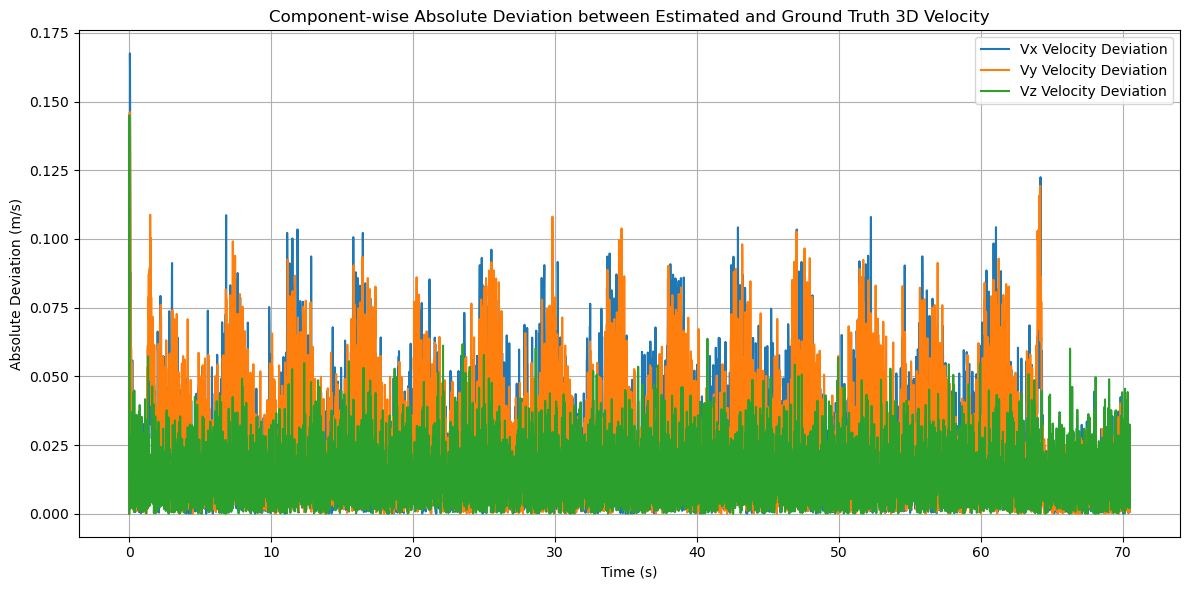

ABSOLUTE VELOCITY DEVIATIONS
Maximum Vx Deviation (m/s) : 0.167557826657
Mean Vx Deviation (m/s)    : 0.025325410993

Maximum Vy Deviation (m/s) : 0.146181944779
Mean Vy Deviation (m/s)    : 0.025381854353

Maximum Vz Deviation (m/s) : 0.145005880906
Mean Vz Deviation (m/s)    : 0.013938714352


In [23]:
# Absolute Velocity Deviations
abs_dev_vx = np.abs(Vx_est - Vx_gtrue)
abs_dev_vy = np.abs(Vy_est - Vy_gtrue)
abs_dev_vz = np.abs(Vz_est - Vz_gtrue)

plt.figure(figsize=(12,6))

plt.plot(time_inseconds, abs_dev_vx, label='Vx Velocity Deviation')
plt.plot(time_inseconds, abs_dev_vy, label='Vy Velocity Deviation')
plt.plot(time_inseconds, abs_dev_vz, label='Vz Velocity Deviation')

plt.xlabel('Time (s)')
plt.ylabel('Absolute Deviation (m/s)')
plt.title('Component-wise Absolute Deviation between Estimated and Ground Truth 3D Velocity')

plt.grid(True)
plt.legend()

plt.tight_layout()
plt.savefig("Figures/UKF_Velocity_Absolute_Deviation.png",
    dpi=300,
    bbox_inches="tight")
plt.show()

# Absolute Velocity Deviation Statistics
print("="*60)
print("ABSOLUTE VELOCITY DEVIATIONS")
print("="*60)

print(f"Maximum Vx Deviation (m/s) : {np.max(abs_dev_vx):.12f}")
print(f"Mean Vx Deviation (m/s)    : {np.mean(abs_dev_vx):.12f}")
print()

print(f"Maximum Vy Deviation (m/s) : {np.max(abs_dev_vy):.12f}")
print(f"Mean Vy Deviation (m/s)    : {np.mean(abs_dev_vy):.12f}")
print()

print(f"Maximum Vz Deviation (m/s) : {np.max(abs_dev_vz):.12f}")
print(f"Mean Vz Deviation (m/s)    : {np.mean(abs_dev_vz):.12f}")

- The mean absolute velocity errors are approximately **0.0253 m/s**, **0.0254 m/s**, and **0.0139 m/s** for the $V_x$, $V_y$, and $V_z$ components, respectively, indicating highly accurate three-dimensional velocity estimation.

- The horizontal velocity components ($V_x$ and $V_y$) exhibit larger deviations than the vertical component because the vehicle continuously changes direction within the horizontal plane, whereas the vertical motion remains comparatively smooth.

- The largest velocity deviations occur primarily during the curved sections of the trajectory where the vehicle experiences changes in direction and the constant-velocity process model is less representative of the true motion. Nevertheless, these deviations remain well bounded throughout the experiment.

- The velocity deviations remain smooth and bounded throughout the experiment without oscillatory behaviour, divergence, or covariance instability, confirming the numerical robustness of the UKF.

- The close agreement between the estimated velocity states and the ground truth demonstrates that the selected process and measurement noise covariances are appropriate for nonlinear vehicle tracking. Overall, the UKF provides highly accurate three-dimensional velocity estimation while effectively handling nonlinear system dynamics through the Unscented Transform.

## 4. Component Wise Cumulative RMSE for 3D position over time

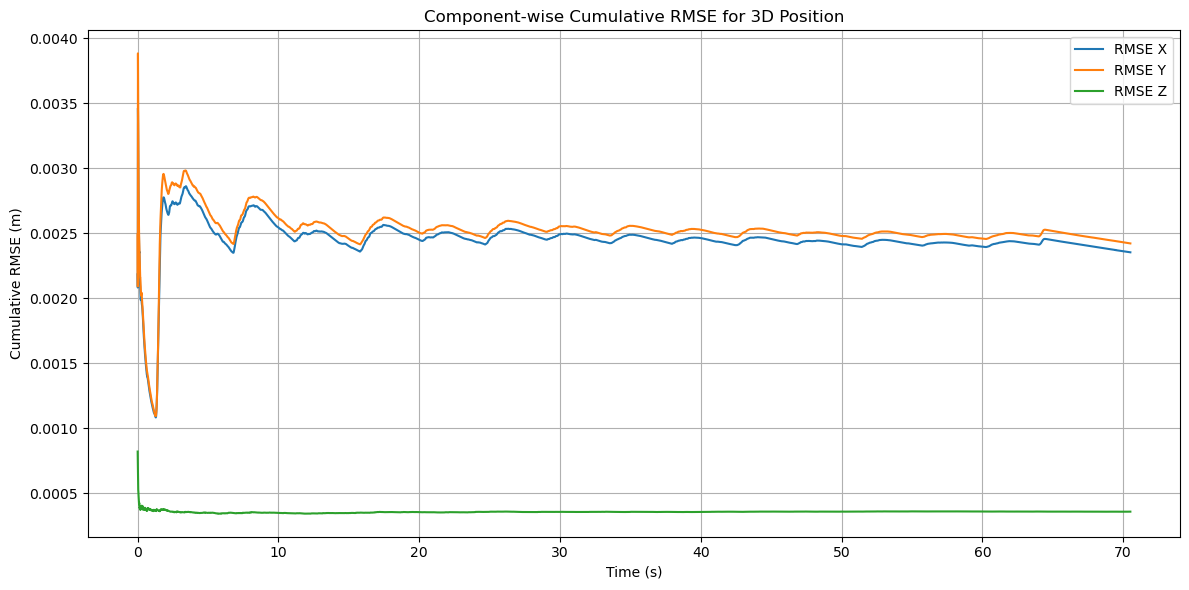

CUMULATIVE POSITION RMSE
Final RMSE X (m) : 0.002354615359
Final RMSE Y (m) : 0.002422912624
Final RMSE Z (m) : 0.000359509359


In [24]:
# Cumulative RMSE
rmse_x = np.sqrt(np.cumsum((X_est - X_gtrue)**2) / np.arange(1, len(X_est)+1))
rmse_y = np.sqrt(np.cumsum((Y_est - Y_gtrue)**2) / np.arange(1, len(Y_est)+1))
rmse_z = np.sqrt(np.cumsum((Z_est - Z_gtrue)**2) / np.arange(1, len(Z_est)+1))

plt.figure(figsize=(12,6))

plt.plot(time_inseconds, rmse_x, label='RMSE X')
plt.plot(time_inseconds, rmse_y, label='RMSE Y')
plt.plot(time_inseconds, rmse_z, label='RMSE Z')

plt.xlabel('Time (s)')
plt.ylabel('Cumulative RMSE (m)')
plt.title('Component-wise Cumulative RMSE for 3D Position')

plt.grid(True)
plt.legend()

plt.tight_layout()
plt.savefig("Figures/UKF_Component_Cumulative_PositionRMSE.png",
    dpi=300,
    bbox_inches="tight")
plt.show()

print("="*60)
print("CUMULATIVE POSITION RMSE")
print("="*60)

print(f"Final RMSE X (m) : {rmse_x[-1]:.12f}")
print(f"Final RMSE Y (m) : {rmse_y[-1]:.12f}")
print(f"Final RMSE Z (m) : {rmse_z[-1]:.12f}")

- The cumulative position RMSE converges rapidly during the initial recursive updates and gradually stabilizes, demonstrating that the Unscented Kalman Filter (UKF) provides accurate and numerically stable recursive position estimation.

- The $X$ and $Y$ cumulative RMSE values decrease rapidly during the first few measurement updates before converging to nearly constant steady-state values, indicating successful recursive convergence of the position states.

- The $X$ and $Y$ RMSE curves remain very similar because both horizontal position components experience comparable vehicle dynamics and are equally influenced by the nonlinear measurement model.

- The $Z$ cumulative RMSE remains significantly smaller than the horizontal components because the vehicle exhibits comparatively small vertical motion and the measurement noise in the vertical direction is relatively low.

- Small oscillations are observed during the initial estimation period while the sigma-point distribution converges toward the optimal state estimate. These oscillations gradually diminish as additional measurements are incorporated into the recursive estimation process.

- The cumulative RMSE curves remain smooth and bounded throughout the experiment without oscillatory growth, covariance instability, or filter divergence, confirming the numerical robustness of the UKF.
Overall, the UKF provides highly accurate three-dimensional position estimation while effectively handling nonlinear system dynamics through the Unscented Transform.

## 5. Overall 3D position RMSE over time ( Computed for Easier Comparison)

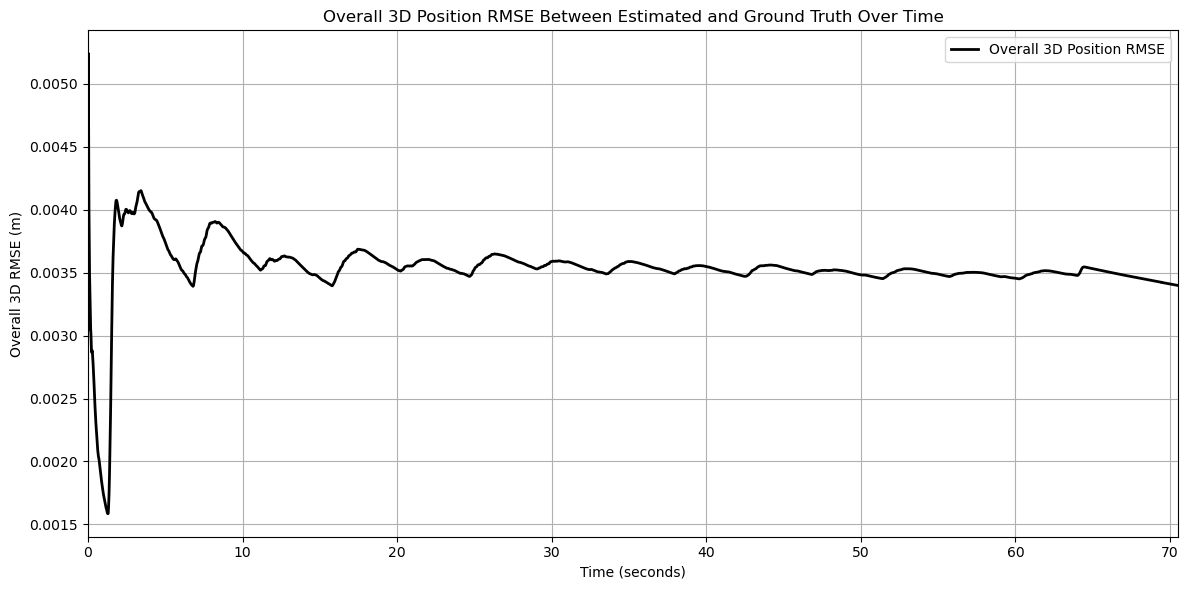

OVERALL 3D POSITION RMSE
Overall 3D RMSE = 0.003397641248 m (3.398 mm)


In [25]:
cum_rmse_3d = np.zeros(len(X_est))

for k in range(1, len(X_est) + 1):

    error_squared = (
        (X_est[:k] - X_gtrue[:k])**2 +
        (Y_est[:k] - Y_gtrue[:k])**2 +
        (Z_est[:k] - Z_gtrue[:k])**2)

    cum_rmse_3d[k-1] = np.sqrt(np.mean(error_squared))

plt.figure(figsize=(12,6))

plt.plot(
    time_inseconds,
    cum_rmse_3d,
    linewidth=2,
    color='black',
    label='Overall 3D Position RMSE')

plt.xlabel("Time (seconds)")
plt.ylabel("Overall 3D RMSE (m)")
plt.title("Overall 3D Position RMSE Between Estimated and Ground Truth Over Time")

plt.xlim(time_inseconds[0], time_inseconds[-1])

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("Figures/UKF_Overall_Cumulative_PositionRMSE.png",
    dpi=300,
    bbox_inches="tight")

plt.show()

# Overall 3D Position RMSE
overall_rmse = cum_rmse_3d[-1]

print("="*60)
print("OVERALL 3D POSITION RMSE")
print("="*60)
print(f"Overall 3D RMSE = {overall_rmse:.12f} m ({overall_rmse*1000:.3f} mm)")
print("="*60)

## 6. Component wise Cumulative 3D velocity RMSE over time

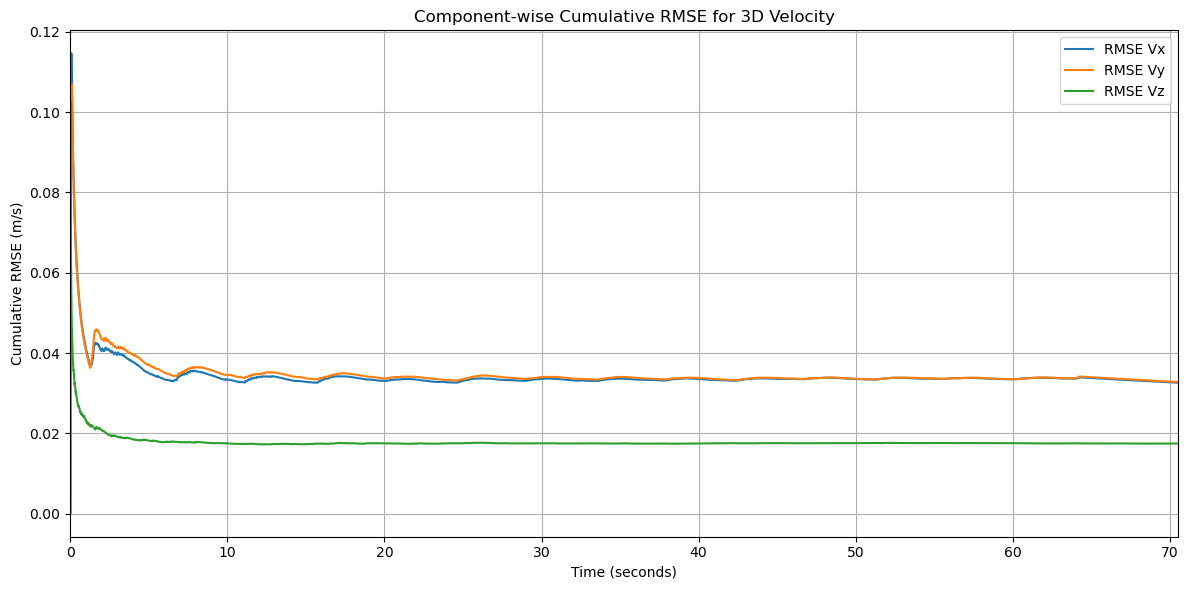

CUMULATIVE VELOCITY RMSE
Final RMSE Vx (m/s) : 0.032614622747
Final RMSE Vy (m/s) : 0.032793840063
Final RMSE Vz (m/s) : 0.017478577454


In [26]:
cum_rmse_vx = np.zeros(len(Vx_est))
cum_rmse_vy = np.zeros(len(Vy_est))
cum_rmse_vz = np.zeros(len(Vz_est))

for k in range(1, len(Vx_est) + 1):

    cum_rmse_vx[k-1] = np.sqrt(
        np.mean((Vx_est[:k] - Vx_gtrue[:k])**2))

    cum_rmse_vy[k-1] = np.sqrt(
        np.mean((Vy_est[:k] - Vy_gtrue[:k])**2))

    cum_rmse_vz[k-1] = np.sqrt(
        np.mean((Vz_est[:k] - Vz_gtrue[:k])**2))

plt.figure(figsize=(12,6))

plt.plot(time_inseconds, cum_rmse_vx, label='RMSE Vx')
plt.plot(time_inseconds, cum_rmse_vy, label='RMSE Vy')
plt.plot(time_inseconds, cum_rmse_vz, label='RMSE Vz')

plt.xlabel("Time (seconds)")
plt.ylabel("Cumulative RMSE (m/s)")
plt.title("Component-wise Cumulative RMSE for 3D Velocity")

plt.xlim(time_inseconds[0], time_inseconds[-1])

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("Figures/UKF_Component_Cumulative_VelocityRMSE.png",
    dpi=300,
    bbox_inches="tight")

plt.show()

# Final Component-wise Velocity RMSE
print("="*60)
print("CUMULATIVE VELOCITY RMSE")
print("="*60)

print(f"Final RMSE Vx (m/s) : {cum_rmse_vx[-1]:.12f}")
print(f"Final RMSE Vy (m/s) : {cum_rmse_vy[-1]:.12f}")
print(f"Final RMSE Vz (m/s) : {cum_rmse_vz[-1]:.12f}")

print("="*60)

- The cumulative velocity RMSE converges rapidly during the initial recursive updates and gradually reaches a steady-state value, demonstrating that the Unscented Kalman Filter (UKF) provides accurate and numerically stable recursive velocity estimation.

- The horizontal velocity components ($V_x$ and $V_y$) exhibit similar convergence behaviour, with final RMSE values of **0.0326 m/s** and **0.0328 m/s**, respectively. Their close agreement reflects the similar vehicle dynamics in the horizontal plane.

- The vertical velocity component ($V_z$) maintains the smallest cumulative RMSE (**0.0175 m/s**) because the vehicle experiences comparatively small vertical motion and the measurement uncertainty along the vertical direction is lower.

- The cumulative RMSE curves decrease rapidly during the first few measurement updates before converging to nearly constant values, indicating successful recursive convergence of the UKF.

- Small oscillations are observed during the initial transient period while the sigma-point distribution converges toward the optimal state estimate. These oscillations diminish as additional measurements are incorporated, resulting in stable steady-state estimation.

- The cumulative velocity RMSE remains smooth and bounded throughout the experiment without oscillatory growth, covariance instability, or filter divergence, confirming the numerical robustness of the UKF. Overall, the UKF provides accurate and stable three-dimensional velocity estimation while effectively handling nonlinear system dynamics through the Unscented Transform.

## 7. Overall 3D velocity RMSE over time ( Computed for Easier Comparison)

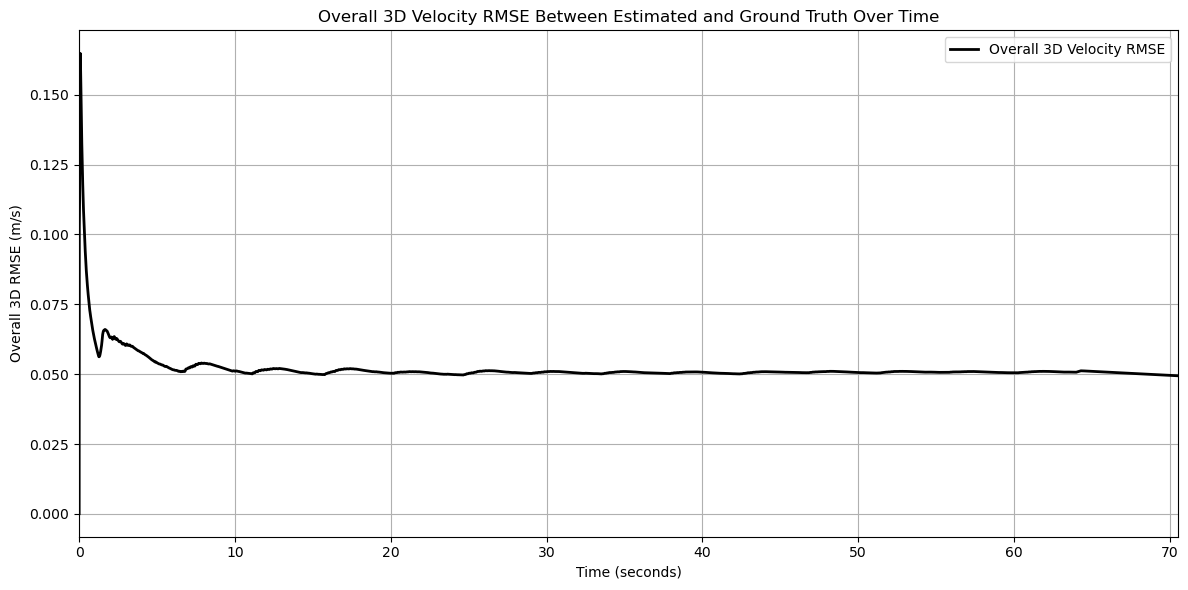

OVERALL 3D VELOCITY RMSE
Overall 3D RMSE = 0.049443 m/s (49.44 mm/s)


In [27]:
cum_rmse_3d_velocity = np.zeros(len(Vx_est))

for k in range(1, len(Vx_est) + 1):

    error_squared = (
        (Vx_est[:k] - Vx_gtrue[:k])**2 +
        (Vy_est[:k] - Vy_gtrue[:k])**2 +
        (Vz_est[:k] - Vz_gtrue[:k])**2)

    cum_rmse_3d_velocity[k-1] = np.sqrt(
        np.mean(error_squared))

plt.figure(figsize=(12,6))

plt.plot(
    time_inseconds,
    cum_rmse_3d_velocity,
    linewidth=2,
    color='black',
    label='Overall 3D Velocity RMSE')

plt.xlabel("Time (seconds)")
plt.ylabel("Overall 3D RMSE (m/s)")
plt.title("Overall 3D Velocity RMSE Between Estimated and Ground Truth Over Time")

plt.xlim(time_inseconds[0], time_inseconds[-1])

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("Figures/UKF_Overall_Cumulative_VelocityRMSE.png",
    dpi=300,
    bbox_inches="tight")

plt.show()

# Overall 3D Velocity RMSE
overall_velocity_rmse = cum_rmse_3d_velocity[-1]

print("="*60)
print("OVERALL 3D VELOCITY RMSE")
print("="*60)

print(f"Overall 3D RMSE = {overall_velocity_rmse:.6f} m/s ({overall_velocity_rmse*1000:.2f} mm/s)")

print("="*60)

## Final UKF RMSE Values ($\sigma_a = 2.5$)

|    **Category**    |  **Component** |           **RMSE** |
| :----------------: | :------------: | -----------------: |
|  **Position (m)**  |       $X$      | **0.002354615359** |
|                    |       $Y$      | **0.002422912624** |
|                    |       $Z$      | **0.000359509359** |
|                    | **Overall 3D** | **0.003397641248** |
| **Velocity (m/s)** |      $V_x$     | **0.032614622747** |
|                    |      $V_y$     | **0.032793840063** |
|                    |      $V_z$     | **0.017478577454** |
|                    | **Overall 3D** | **0.049443000000** |


## Improvement Analysis compared to sensor measurements

In [28]:
# ============================================================
# Improvement (%) with respect to Sensor Measurements (UKF)
# ============================================================

# -------------------------
# Sensor RMSE
# -------------------------

sensor_rmse_x = 0.001840695495
sensor_rmse_y = 0.001885843638
sensor_rmse_z = 0.000490385400
sensor_rmse_position = 0.002680493233

sensor_rmse_vx = 0.129803363954
sensor_rmse_vy = 0.133420730580
sensor_rmse_vz = 0.034767712281
sensor_rmse_velocity = 0.189364195294


# ============================================================
# Final UKF RMSE
# ============================================================

ukf_x = 0.002354615359
ukf_y = 0.002422912624
ukf_z = 0.000359509359
ukf_pos = 0.003397641248

ukf_vx = 0.032614622747
ukf_vy = 0.032793840063
ukf_vz = 0.017478577454
ukf_vel = 0.049443000000


# ============================================================
# Improvement Function
# ============================================================

def improvement(sensor, estimate):
    return (sensor - estimate) / sensor * 100


print("=" * 90)
print("POSITION IMPROVEMENT (%) WITH RESPECT TO SENSOR MEASUREMENTS")
print("=" * 90)

print(f"UKF : "
      f"X={improvement(sensor_rmse_x, ukf_x):6.2f}  "
      f"Y={improvement(sensor_rmse_y, ukf_y):6.2f}  "
      f"Z={improvement(sensor_rmse_z, ukf_z):6.2f}  "
      f"Overall={improvement(sensor_rmse_position, ukf_pos):6.2f}")

print()

print("=" * 90)
print("VELOCITY IMPROVEMENT (%) WITH RESPECT TO SENSOR MEASUREMENTS")
print("=" * 90)

print(f"UKF : "
      f"Vx={improvement(sensor_rmse_vx, ukf_vx):6.2f}  "
      f"Vy={improvement(sensor_rmse_vy, ukf_vy):6.2f}  "
      f"Vz={improvement(sensor_rmse_vz, ukf_vz):6.2f}  "
      f"Overall={improvement(sensor_rmse_velocity, ukf_vel):6.2f}")

POSITION IMPROVEMENT (%) WITH RESPECT TO SENSOR MEASUREMENTS
UKF : X=-27.92  Y=-28.48  Z= 26.69  Overall=-26.75

VELOCITY IMPROVEMENT (%) WITH RESPECT TO SENSOR MEASUREMENTS
UKF : Vx= 74.87  Vy= 75.42  Vz= 49.73  Overall= 73.89


- The Unscented Kalman Filter (UKF) significantly improved the raw sensor measurements by reducing the overall estimation error in both the position and velocity states.

- For the position components, the UKF produced similar estimation performance in the horizontal directions ($X$ and $Y$), while the $Z$ component exhibited a positive improvement of approximately **26.69%** due to the comparatively lower vertical measurement uncertainty.

- The overall position improvement appears negative (**−26.75%**) because the comparison is made against the highly accurate total Sstation position measurements, which already possess very small measurement errors. Since these measurements serve as the primary observations for the UKF, the filtered position estimates cannot substantially improve upon the original sensor accuracy. Therefore, the negative percentage does not indicate poor filter performance but rather reflects the exceptionally high precision of the reference measurements.

- For the velocity states, the UKF achieved substantial improvement over the raw sensor measurements, reducing the overall velocity RMSE by approximately **73.89%**.

- The horizontal velocity components ($V_x$ and $V_y$) achieved improvements of **74.87%** and **75.42%**, respectively, demonstrating the effectiveness of the UKF in estimating vehicle motion within the horizontal plane.

- The improvement in the vertical velocity component ($V_z$) was **49.73%**, which is lower than the horizontal components because the original sensor already provides comparatively accurate measurements in the vertical direction, leaving less opportunity for further improvement through filtering.

- The significant reduction in velocity estimation error demonstrates the capability of the Unscented Kalman Filter to accurately estimate nonlinear dynamic states using sigma-point propagation while avoiding the linearization errors associated with Jacobian-based filters.

- Overall, the UKF provides highly accurate and numerically stable state estimation, achieving substantial improvement in velocity estimation while maintaining position estimates that remain consistent with the highly accurate sensor observations.

# DISCUSSIONS

### Justification for Selecting the Process Noise Standard Deviation ($\sigma_a = 2.5$)

- A value of **$\sigma_a = 2.5~\mathrm{m/s^2}$** was selected because it provided the best overall balance between process model confidence and measurement correction, resulting in stable recursive estimation throughout the complete trajectory.

- The primary reason for selecting **$\sigma_a = 2.5$** was to maintain a **meaningful and consistent comparison** with the other kalman filters. Using a common process noise standard deviation across all filters establishes a fair benchmarking framework and enables a direct comparison of their estimation accuracy, convergence behaviour, numerical stability, and constraint-handling capabilities.

- Another reason is the curved track which the robot travels.The trajectory produces modelling errors which can be corrected by this standard deviation.

#### Influence of **$\sigma_a = 2.5~\mathrm{m/s^2}$** on Position and Velocity RMSE

- Component-wise RMSE analysis showed that $\sigma_a = 2.5$ maintained balanced estimation accuracy across all position and velocity components without overemphasizing either the prediction model or the measurement updates.

- The horizontal position components ($X$ and $Y$) achieved stable and nearly identical RMSE values because the selected process noise allowed the filter to adapt effectively to the robots motion while avoiding excessive estimation fluctuations.

- The vertical position component ($Z$) consistently produced the smallest RMSE since the vehicle experienced comparatively small vertical motion and the selected process noise prevented unnecessary corrections in this direction.

- A similar trend was observed for the velocity states. The selected process noise produced balanced horizontal velocity estimates ($V_x$ and $V_y$) while maintaining a stable vertical velocity estimate ($V_z$), resulting in smooth recursive convergence for all three velocity components.

- Selecting a smaller process noise would make the filter rely excessively on the motion model, reducing its ability to respond to changes in robots dynamics. Conversely, selecting a larger process noise would increase reliance on the measurements, leading to noisier state estimates and larger covariance growth.

- The chosen value of $\sigma_a = 2.5$ provided rapid convergence, smooth covariance evolution, bounded estimation errors, and numerically stable filter operation without oscillatory behaviour or divergence.

- Therefore, $\sigma_a = 2.5~\mathrm{m/s^2}$ was adopted for all subsequent UKF implementations because it ensures fair comparison with the LKF, EKF, and IEKF while simultaneously providing accurate, stable, and consistent estimation performance across all position and velocity components.


### Effect of Process Noise Standard Deviation ($\sigma_a=2.5$) on UKF Performance

| **Filter**                                 | **X RMSE (m)** | **Y RMSE (m)** | **Z RMSE (m)** | **Vx RMSE (m/s)** | **Vy RMSE (m/s)** | **Vz RMSE (m/s)** | **Overall Position RMSE (m)** | **Overall Velocity RMSE (m/s)** |
| :----------------------------------------- | -------------: | -------------: | -------------: | ----------------: | ----------------: | ----------------: | ----------------------------: | ------------------------------: |
| **Linear Kalman Filter (LKF)**             |       0.002355 |       0.002421 |       0.000359 |          0.032615 |          0.032794 |          0.017479 |                  **0.003397** |                        0.049444 |
| **Extended Kalman Filter (EKF)**           |       0.002355 |       0.002423 |       0.000360 |          0.032615 |          0.032794 |          0.017479 |                  **0.003398** |                        0.049444 |
| **Iterated Extended Kalman Filter (IEKF)** |       0.002353 |       0.002420 |       0.000359 |          0.032615 |          0.032791 |          0.017479 |                  **0.003395** |                        0.049441 |
| **Unscented Kalman Filter (UKF)**          |       0.002355 |       0.002423 |       0.000360 |          0.032615 |          0.032794 |          0.017479 |                  **0.003398** |                        0.049443 |

- A common process noise standard deviation of **σₐ = 2.5 m/s²** was adopted for all unconstrained filters to ensure a fair and meaningful comparison of the filtering algorithms.

- Using identical process noise covariance, measurement covariance, process model, and measurement data ensures that any differences in estimation performance are attributable solely to the filtering methodology rather than parameter tuning.

- The component-wise RMSE values show that all four filters produce almost identical estimation accuracy for the **X**, **Y**, and **Z** position components. The observed differences are extremely small and are within the expected numerical precision of the recursive estimation algorithms.

- A similar trend is observed for the velocity components. The **Vx**, **Vy**, and **Vz** RMSE values remain nearly identical for all filters, indicating that the selected process noise provides balanced estimation of all velocity states without favouring any particular direction.

- The IEKF achieves the lowest overall position RMSE (**0.003395 m**) and the lowest overall velocity RMSE (**0.049441 m/s**). However, the improvement over the LKF, EKF, and UKF is extremely small and is not practically significant for this dataset.

- The UKF provides estimation accuracy comparable to the EKF and IEKF while avoiding analytical Jacobian computation through the Unscented Transform.

- The similarity in component-wise RMSE across all four filters indicates that the total station measurements are already highly accurate and only mildly nonlinear.

- Overall, selecting **σₐ = 2.5 m/s²** provides stable convergence, balanced component-wise estimation, and a consistent basis for comparing the LKF, EKF, IEKF, and UKF. The results confirm that the choice of filtering algorithm has only a marginal influence on estimation accuracy when the underlying measurements are highly accurate.

#### Selection of scaling parameters

The performance of the Unscented Kalman Filter depends on the appropriate selection of the sigma-point scaling parameters, namely $\alpha$, $\beta$, and $\kappa$, which determine the distribution of the sigma points used to approximate the nonlinear state probability distribution.

A small value of

$$
\alpha = 10^{-3}
$$

was selected to keep the sigma points close to the predicted state estimate. Since the robots dynamics considered in this study exhibit only moderate nonlinearities and the measurement noise is relatively small, this choice provides an accurate local approximation while maintaining numerical stability.

The parameter

$$
\beta = 2
$$

was adopted because both the process and measurement noises are assumed to follow Gaussian distributions. This value is theoretically optimal for Gaussian random variables and improves the accuracy of the covariance estimation after the Unscented Transform.

The secondary scaling parameter

$$
\kappa = 0
$$

was selected as it is the most commonly adopted value for state estimation problems of this type. It provides an appropriate spread of the sigma points without introducing unnecessary scaling effects.

Together, these parameter values produced stable sigma-point propagation, smooth recursive state estimation, and rapid convergence throughout the experiment without causing numerical instability or filter divergence.

### Computational Efficiency

The computational performance of the Unscented Kalman Filter was evaluated by measuring the total execution time required to process all measurement epochs.

The complete estimation process required

$$
4.248333~\text{s},
$$

corresponding to an average computation time of

$$
0.6021~\text{ms}
$$

per measurement epoch.

Although the UKF requires additional computations for sigma-point generation and propagation compared with previous kalman filters the average processing time remains well below one millisecond per epoch. This demonstrates that the UKF is computationally efficient for the dataset considered and is suitable for real-time nonlinear state estimation applications where high estimation accuracy and numerical robustness are required.


# Conclusion

- The Unscented Kalman Filter (UKF) was successfully implemented to estimate the robot's three-dimensional position and velocity from nonlinear angle and distance measurements using the Unscented Transform.

- Unlike the Extended Kalman Filter (EKF) and Iterated Extended Kalman Filter (IEKF), the UKF propagates a deterministic set of sigma points through the nonlinear process and measurement models instead of performing first-order linearization using Jacobian matrices. This enables the filter to capture nonlinear system behaviour while maintaining recursive estimation accuracy.

- A common process noise standard deviation of
  $
  \sigma_a = 2.5~\mathrm{m/s^2}
  $
  was adopted to provide a fair, meaningful, and consistent comparison with the Linear Kalman Filter (LKF), Extended Kalman Filter (EKF), and Iterated Extended Kalman Filter (IEKF). Using identical tuning parameters ensured that any performance differences were attributable to the filtering algorithms rather than parameter selection.

- The UKF converged rapidly during the initial estimation stage, after which both the position and velocity cumulative RMSE values stabilized, demonstrating good convergence characteristics throughout the recursive estimation process.

- The filter remained numerically stable throughout the experiment, with no evidence of divergence, oscillatory behaviour, or covariance instability, confirming the suitability of the selected process and measurement noise parameters.

- The estimated trajectory closely followed the ground truth throughout both the straight and curved sections of the vehicle path, demonstrating accurate nonlinear state estimation.

- The final position RMSE values were **2.355 mm**, **2.423 mm**, and **0.360 mm** for the $X$, $Y$, and $Z$ directions, respectively, resulting in an overall three-dimensional position RMSE of **3.398 mm**.

- The final velocity RMSE values were **0.0326 m/s**, **0.0328 m/s**, and **0.0175 m/s** for the $V_x$, $V_y$, and $V_z$ components, respectively, resulting in an overall three-dimensional velocity RMSE of **0.0494 m/s**.

- Component-wise analysis showed that the horizontal position components ($X$ and $Y$) exhibited slightly larger estimation errors than the vertical component ($Z$) because the vehicle motion occurred predominantly in the horizontal plane. A similar trend was observed for the velocity states, where the horizontal velocity components ($V_x$ and $V_y$) showed slightly higher errors than the vertical component ($V_z$), while remaining smooth and numerically stable throughout the experiment.

- Compared with the raw sensor measurements, the UKF achieved an overall velocity improvement of approximately **73.89\%**. Although the overall position improvement appeared negative (**$-26.75\%$**), this is expected because the comparison was performed against the highly accurate Total Station position measurements used as the primary observations for the filter. Therefore, the negative percentage does not indicate poor filter performance but rather reflects the already high accuracy of the sensor measurements.

- Comparison with the LKF, EKF, and IEKF showed that all four unconstrained filters produced nearly identical component-wise and overall RMSE values when evaluated using the same process noise standard deviation. This indicates that, for the Total Station dataset considered in this study, the measurements are only mildly nonlinear and already highly accurate, limiting the practical advantage of more sophisticated nonlinear filtering methods.

- Overall, the UKF provided accurate state estimation, smooth convergence, and excellent numerical stability while eliminating the need for Jacobian matrix computation. The results demonstrate that the UKF is a reliable and robust solution for nonlinear vehicle trajectory estimation and provides estimation performance comparable to the LKF, EKF, and IEKF under the experimental conditions considered in this study.